In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
data = pd.read_csv("loan_approval_data.csv")

data.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [3]:
df = pd.DataFrame(data)

df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [4]:
# df.info()
# df.isnull().sum()
df.describe()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,501.220000,10852.571579,5082.455789,39.971579,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,20522.825263,48.000000
std,289.608451,5061.632859,2943.161570,11.139797,1.105067,71.346015,1.406246,0.144341,5860.736885,14345.696031,11504.142575,24.245322
min,1.000000,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,1015.000000,12.000000
25%,250.250000,6730.750000,2472.750000,30.250000,1.000000,616.250000,1.000000,0.220000,4760.250000,12698.250000,9806.250000,24.000000
50%,499.500000,10548.000000,5205.500000,40.000000,1.000000,678.000000,2.000000,0.340000,9880.500000,24321.000000,21210.500000,48.000000
75%,752.750000,15190.000000,7620.750000,49.000000,2.000000,737.000000,3.000000,0.480000,15074.500000,36947.000000,30263.000000,72.000000
max,1000.000000,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,84.000000


# Handle Missing Values

In [5]:
numerical_columns = df.select_dtypes(include=["number"]).columns



categorical_columns = df.select_dtypes(include=["object"]).columns

In [6]:
from sklearn.impute import SimpleImputer

num_imp = SimpleImputer(strategy = "mean")
df[numerical_columns] = num_imp.fit_transform(df[numerical_columns])

cat_imp = SimpleImputer(strategy = "most_frequent")
df[categorical_columns] = cat_imp.fit_transform(df[categorical_columns])


In [7]:
df.isnull().sum()

Applicant_ID          0
Applicant_Income      0
Coapplicant_Income    0
Employment_Status     0
Age                   0
Marital_Status        0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
Loan_Purpose          0
Property_Area         0
Education_Level       0
Gender                0
Employer_Category     0
Loan_Approved         0
dtype: int64

# EDA: Exploratory Data Analysis


Text(0.5, 1.0, 'Is loan approved or not')

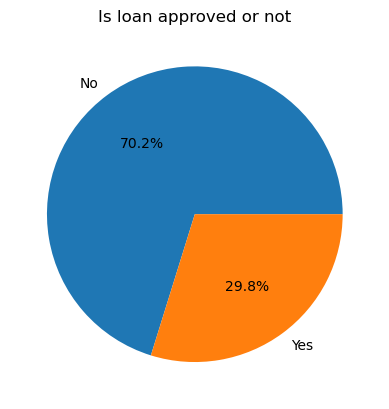

In [41]:
# check for how data is balanced

classes_count = df["Loan_Approved"].value_counts()
plt.pie(classes_count, labels = ["No","Yes"], autopct = "%1.1f%%")
plt.title("Is loan approved or not")


[Text(0, 0, '621'), Text(0, 0, '379')]

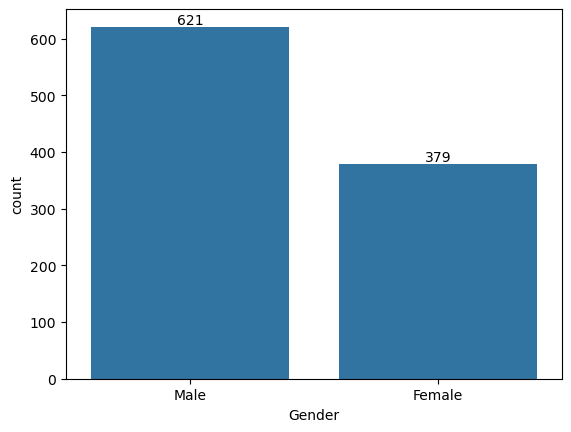

In [9]:
#Gender Count

gender_count = df["Gender"].value_counts()

ax = sns.barplot(gender_count)

ax.bar_label(ax.containers[0])

[Text(0, 0, '722'), Text(0, 0, '278')]

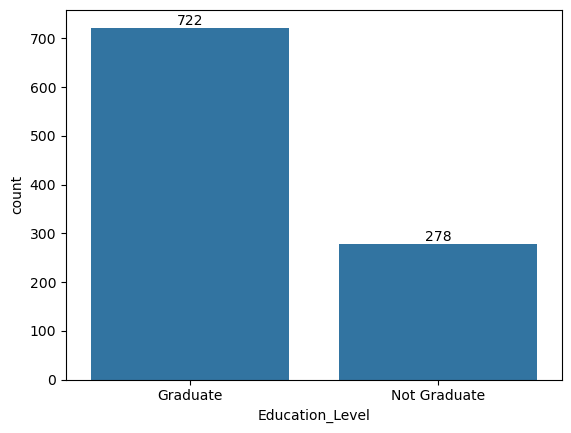

In [10]:
edu_level = df["Education_Level"].value_counts()

ax = sns.barplot(edu_level)

ax.bar_label(ax.containers[0])

[Text(0, 0, '422'),
 Text(0, 0, '202'),
 Text(0, 0, '144'),
 Text(0, 0, '135'),
 Text(0, 0, '97')]

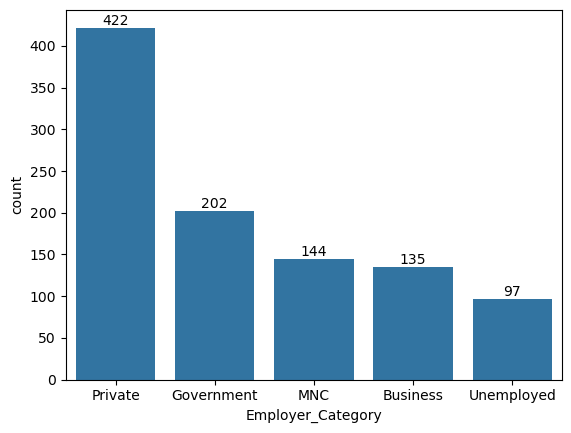

In [11]:
emp_catagory = df["Employer_Category"].value_counts()

ax = sns.barplot(emp_catagory)

ax.bar_label(ax.containers[0])

<Axes: xlabel='Applicant_Income', ylabel='Count'>

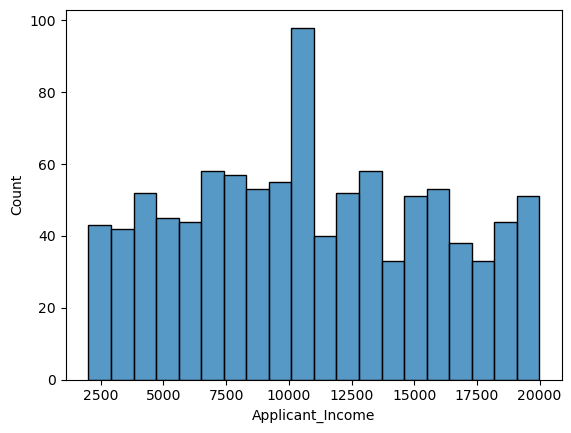

In [12]:
#applicants income

sns.histplot(
    data = df,
    x = "Applicant_Income",
    bins = 20
)

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

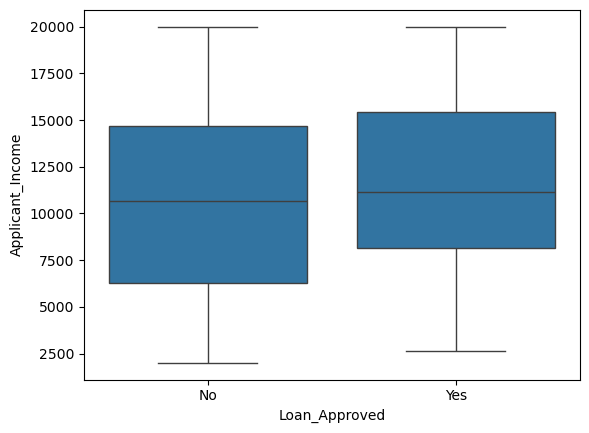

In [13]:
#boc plot for detecting ouliers

sns.boxplot(
    data = df,
    x = "Loan_Approved",
    y = "Applicant_Income"
)

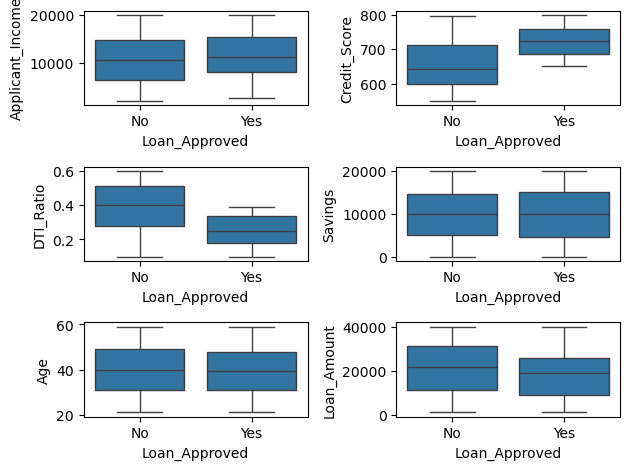

In [14]:
fig, axes = plt.subplots(3,2)

sns.boxplot(ax = axes[0,0], data = df, x = "Loan_Approved", y = "Applicant_Income")
sns.boxplot(ax = axes[0,1], data = df, x = "Loan_Approved", y = "Credit_Score")
sns.boxplot(ax = axes[1,0], data = df, x = "Loan_Approved", y = "DTI_Ratio")
sns.boxplot(ax = axes[1,1], data = df, x = "Loan_Approved", y = "Savings")
sns.boxplot(ax = axes[2,0], data = df, x = "Loan_Approved", y = "Age")
sns.boxplot(ax = axes[2,1], data = df, x = "Loan_Approved", y = "Loan_Amount")

plt.tight_layout()

<Axes: xlabel='Credit_Score', ylabel='Count'>

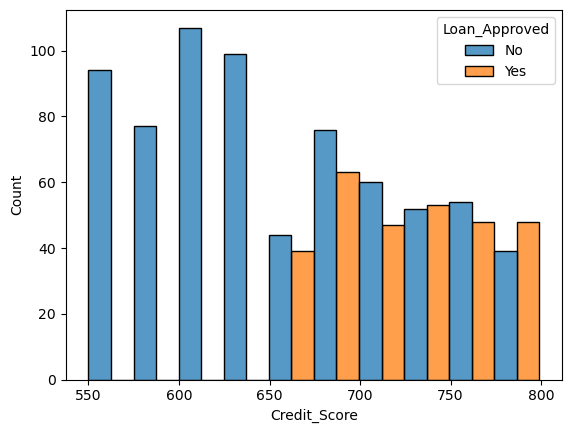

In [15]:
#check loan approval based on credit score

sns.histplot(
    data = df,
    x = "Credit_Score",
    hue = "Loan_Approved",
    bins = 10,
    multiple = "dodge"
)

    

<Axes: xlabel='Applicant_Income', ylabel='Count'>

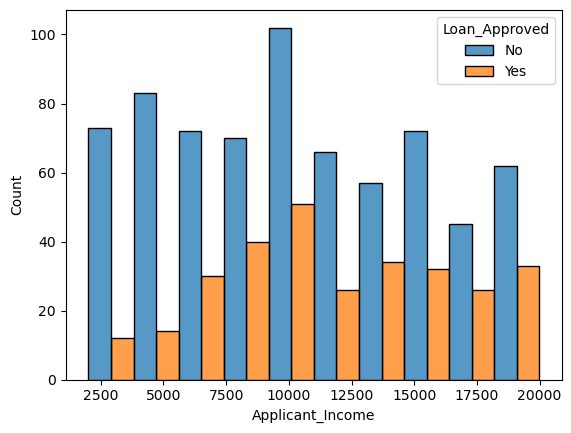

In [16]:
sns.histplot(
    data = df,
    x = "Applicant_Income",
    hue = "Loan_Approved",
    bins = 10,
    multiple = "dodge"
)

In [17]:
# remove un-necessary columns

df = df.drop("Applicant_ID",axis = 1)

df.head(5)


,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


# Encoding

In [18]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

le = LabelEncoder()

df["Education_Level"] = le.fit_transform(df["Education_Level"])
df["Loan_Approved"] = le.fit_transform(df["Loan_Approved"])


cols = ["Employment_Status","Marital_Status","Gender","Employer_Category","Loan_Purpose","Property_Area"]

ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")

encoded = ohe.fit_transform(df[cols])

encoded_df = pd.DataFrame(encoded,columns = ohe.get_feature_names_out(cols),index=df.index)

encoded_df.head()

,Employment_Status_Salaried,Employment_Status_Self-employed,Employment_Status_Unemployed,Marital_Status_Single,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [19]:
# add changed columns to original dataframe

df = pd.concat([df.drop(columns = cols),encoded_df],axis = 1)

df.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban
0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Applicant_Income                 1000 non-null   float64
 1   Coapplicant_Income               1000 non-null   float64
 2   Age                              1000 non-null   float64
 3   Dependents                       1000 non-null   float64
 4   Credit_Score                     1000 non-null   float64
 5   Existing_Loans                   1000 non-null   float64
 6   DTI_Ratio                        1000 non-null   float64
 7   Savings                          1000 non-null   float64
 8   Collateral_Value                 1000 non-null   float64
 9   Loan_Amount                      1000 non-null   float64
 10  Loan_Term                        1000 non-null   float64
 11  Education_Level                  1000 non-null   int64  
 12  Loan_Approved        

# Correlation heatMap


In [21]:
num_cols = df.select_dtypes(include="number")

corr_matrix = num_cols.corr()

num_cols.corr()["Loan_Approved"].sort_values(ascending = False)

Loan_Approved                      1.000000
Credit_Score                       0.451175
Applicant_Income                   0.119796
Employer_Category_MNC              0.069049
Loan_Purpose_Personal              0.034043
Marital_Status_Single              0.030182
Property_Area_Urban                0.025963
Collateral_Value                   0.021868
Coapplicant_Income                 0.004230
Loan_Purpose_Home                  0.002118
Employment_Status_Self-employed   -0.001337
Employer_Category_Private         -0.003347
Property_Area_Semiurban           -0.012967
Savings                           -0.013437
Loan_Purpose_Education            -0.016684
Employer_Category_Unemployed      -0.021468
Age                               -0.022343
Dependents                        -0.023811
Existing_Loans                    -0.034794
Employer_Category_Government      -0.039187
Employment_Status_Salaried        -0.041428
Employment_Status_Unemployed      -0.044464
Education_Level                 

<Axes: >

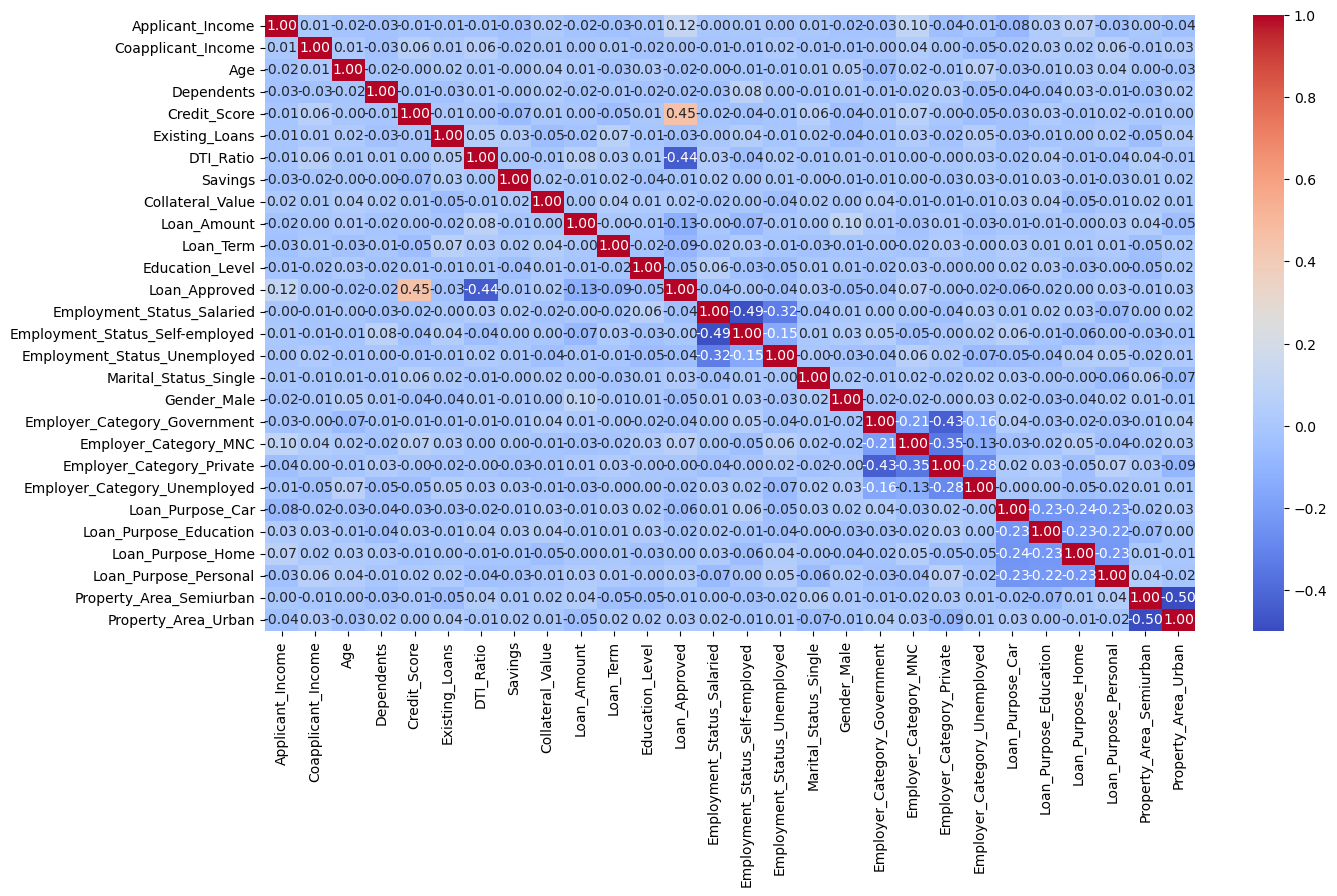

In [22]:
plt.figure(figsize=(15,8))

sns.heatmap(
    corr_matrix,
    annot = True,
    fmt = ".2f",
    cmap = "coolwarm"
)

# Train test split

In [23]:
X = df.drop("Loan_Approved",axis = 1)


In [24]:
y = df["Loan_Approved"]

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size = 0.2,random_state = 42
)

In [26]:
# X_train.head()
# X_test.head()
# y_train.head()
# y_test.head()

In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [28]:
X_test_scaled

array([[ 0.42610546,  0.55091079,  1.19037073, ..., -0.46454867,
         2.081666  , -1.05395348],
       [ 1.00971366,  0.58995935,  0.18392964, ..., -0.46454867,
        -0.48038446, -1.05395348],
       [-0.67557096, -0.54558674,  1.09887608, ..., -0.46454867,
        -0.48038446, -1.05395348],
       ...,
       [-0.67980585, -0.10106072,  1.28186537, ..., -0.46454867,
        -0.48038446, -1.05395348],
       [-0.37650705, -0.97825874, -0.54802752, ..., -0.46454867,
        -0.48038446, -1.05395348],
       [-0.73647272, -1.24497436,  0.73289751, ..., -0.46454867,
        -0.48038446, -1.05395348]], shape=(200, 27))

# train & evaluate models

### Logistic regression

In [29]:
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

log_model = LogisticRegression()

log_model.fit(X_train_scaled,y_train)

y_predt = log_model.predict(X_test_scaled)

In [30]:
# Evaluation
print("........Logstic Regression Model........")
print("precision: ",precision_score(y_test,y_predt))
print("accuracy: ",accuracy_score(y_test,y_predt))
print("recall: ",recall_score(y_test,y_predt))
print("fl_score: ",f1_score(y_test,y_predt))
print("confusion matrix ",confusion_matrix(y_test,y_predt))


........Logstic Regression Model........
precision:  0.7833333333333333
accuracy:  0.865
recall:  0.7704918032786885
fl_score:  0.7768595041322314
confusion matrix  [[126  13]
 [ 14  47]]


# KNN


In [31]:
from sklearn.neighbors import KNeighborsClassifier 

knn_model = KNeighborsClassifier(n_neighbors=3)

knn_model.fit(X_train_scaled,y_train)

y_predt = knn_model.predict(X_test_scaled)

In [32]:
# Evaluation
print("........KNN Model........")
print("precision: ",precision_score(y_test,y_predt))
print("accuracy: ",accuracy_score(y_test,y_predt))
print("recall: ",recall_score(y_test,y_predt))
print("fl_score: ",f1_score(y_test,y_predt))
print("confusion matrix ",confusion_matrix(y_test,y_predt))


........KNN Model........
precision:  0.5737704918032787
accuracy:  0.74
recall:  0.5737704918032787
fl_score:  0.5737704918032787
confusion matrix  [[113  26]
 [ 26  35]]


# Naive Bayes

In [33]:
from sklearn.naive_bayes import GaussianNB 

nb_model = GaussianNB()

nb_model.fit(X_train_scaled,y_train)

y_predt = nb_model.predict(X_test_scaled)

In [34]:
# Evaluation
print("........naive bayes Model........")
print("precision: ",precision_score(y_test,y_predt))
print("accuracy: ",accuracy_score(y_test,y_predt))
print("recall: ",recall_score(y_test,y_predt))
print("fl_score: ",f1_score(y_test,y_predt))
print("confusion matrix ",confusion_matrix(y_test,y_predt))


........naive bayes Model........
precision:  0.8035714285714286
accuracy:  0.865
recall:  0.7377049180327869
fl_score:  0.7692307692307693
confusion matrix  [[128  11]
 [ 16  45]]


# Feature Engineering

In [35]:
# Add and transform features

df["DTI_ratio_sq"] = df["DTI_Ratio"]**2
df["Credit_Score_sq"] = df["Credit_Score"]**2

X = df.drop(columns=["Loan_Approved","Credit_Score","DTI_Ratio"])

y = df["Loan_Approved"]

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size = 0.2,random_state = 42
)

In [37]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [38]:
#LogisticRegression
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

log_model = LogisticRegression()

log_model.fit(X_train_scaled,y_train)

y_predt = log_model.predict(X_test_scaled)

# Evaluation
print("........Logstic Regression Model........")
print("precision: ",precision_score(y_test,y_predt))
print("accuracy: ",accuracy_score(y_test,y_predt))
print("recall: ",recall_score(y_test,y_predt))
print("fl_score: ",f1_score(y_test,y_predt))
print("confusion matrix ",confusion_matrix(y_test,y_predt))


........Logstic Regression Model........
precision:  0.7903225806451613
accuracy:  0.875
recall:  0.8032786885245902
fl_score:  0.7967479674796748
confusion matrix  [[126  13]
 [ 12  49]]


In [39]:
#KNeighborsClassifier

from sklearn.neighbors import KNeighborsClassifier 

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled,y_train)

y_predt = knn_model.predict(X_test_scaled)

# Evaluation
print("........KNN Model........")
print("precision: ",precision_score(y_test,y_predt))
print("accuracy: ",accuracy_score(y_test,y_predt))
print("recall: ",recall_score(y_test,y_predt))
print("fl_score: ",f1_score(y_test,y_predt))
print("confusion matrix ",confusion_matrix(y_test,y_predt))



........KNN Model........
precision:  0.62
accuracy:  0.755
recall:  0.5081967213114754
fl_score:  0.5585585585585585
confusion matrix  [[120  19]
 [ 30  31]]


In [40]:
#GaussianNB

from sklearn.naive_bayes import GaussianNB 

nb_model = GaussianNB()

nb_model.fit(X_train_scaled,y_train)

y_predt = nb_model.predict(X_test_scaled)

# Evaluation
print("........naive bayes Model........")
print("precision: ",precision_score(y_test,y_predt))
print("accuracy: ",accuracy_score(y_test,y_predt))
print("recall: ",recall_score(y_test,y_predt))
print("fl_score: ",f1_score(y_test,y_predt))
print("confusion matrix ",confusion_matrix(y_test,y_predt))


........naive bayes Model........
precision:  0.7833333333333333
accuracy:  0.865
recall:  0.7704918032786885
fl_score:  0.7768595041322314
confusion matrix  [[126  13]
 [ 14  47]]


### Best model on the basis of precision, recall & f1 score is Logistic regression